# 1. Exploração Inicial:
Nesta etapa, será realizada a exploração estrutural da base de dados de vendas, com o objetivo de conhecer sua dimensão, identificar os tipos de dados de cada variável e verificar possíveis problemas iniciais de qualidade.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Lendo a base de dados e criando um dataframe com os dados brutos.
df_vendas = pd.read_csv('vendas.csv',sep=';')

#Exploração estrutural do DataFrame
df_vendas.info()



<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_item_venda      50000 non-null  int64  
 1   id_pedido          50000 non-null  int64  
 2   data_venda         50000 non-null  str    
 3   nome_produto       50000 non-null  str    
 4   categoria_produto  50000 non-null  str    
 5   quantidade         50000 non-null  int64  
 6   preco_unitario     50000 non-null  float64
 7   desconto           50000 non-null  float64
 8   valor_total        50000 non-null  float64
 9   nome_cliente       50000 non-null  str    
 10  cidade_cliente     49850 non-null  str    
 11  estado_cliente     50000 non-null  str    
 12  nome_vendedor      50000 non-null  str    
 13  forma_pagamento    50000 non-null  str    
 14  status_venda       50000 non-null  str    
dtypes: float64(3), int64(3), str(9)
memory usage: 5.7 MB


### Análise estrutural

A base de dados apresenta 50.000 registros distribuídos em 15 colunas, contendo informações sobre vendas, produtos, clientes e vendedores.

Durante a exploração, foi identificado que a coluna data_venda está armazenada como texto (str), sendo necessária sua conversão para o formato de data posteriormente.

Também foram identificados 150 valores ausentes na coluna cidade_cliente. As demais colunas apresentam preenchimento completo.

# 2. Tratamento dos Dados

Nesta etapa, serão identificados e tratados valores ausentes, registros duplicados e possíveis inconsistências na base de dados.

In [2]:
#Verificando a quantidade de valores ausentes em cada coluna.
df_vendas.isna().sum()

id_item_venda          0
id_pedido              0
data_venda             0
nome_produto           0
categoria_produto      0
quantidade             0
preco_unitario         0
desconto               0
valor_total            0
nome_cliente           0
cidade_cliente       150
estado_cliente         0
nome_vendedor          0
forma_pagamento        0
status_venda           0
dtype: int64

In [3]:
#Substituindo os valores ausentes da coluna cidade_cliente por "Não informado".
df_vendas['cidade_cliente'] = df_vendas['cidade_cliente'].fillna('Não informado')

#Confirmando substituição de dados ausentes na coluna cidade_cliente.
df_vendas.isna().sum()

id_item_venda        0
id_pedido            0
data_venda           0
nome_produto         0
categoria_produto    0
quantidade           0
preco_unitario       0
desconto             0
valor_total          0
nome_cliente         0
cidade_cliente       0
estado_cliente       0
nome_vendedor        0
forma_pagamento      0
status_venda         0
dtype: int64

In [4]:
#Verificando a quantidade de registros duplicados na base de vendas.
df_vendas.duplicated().sum()

np.int64(150)

In [5]:
#Removendo os registros duplicados da base de vendas.
df_vendas = df_vendas.drop_duplicates()

#Confirmando a ausência de registros duplicados após o tratamento.
df_vendas.duplicated().sum()

np.int64(0)

In [6]:
#Convertendo a coluna data_venda para datetime e mantendo datas inválidas como NaT.
df_vendas['data_venda'] = pd.to_datetime(
    df_vendas['data_venda'],
    format='%Y-%m-%d %H:%M:%S',
    errors='coerce')

#Verificando a quantidade de datas inválidas após a conversão.
df_vendas['data_venda'].isna().sum()

np.int64(149)

In [7]:
#Identificando possíveis erros de digitação na coluna status_venda.
df_vendas['status_venda'].value_counts()

status_venda
Concluído    42430
Cancelado     3913
Pendente      1942
Devolvido     1565
Name: count, dtype: int64

In [8]:
#Identificando possíveis erros de digitação na coluna forma_pagamento.
df_vendas['forma_pagamento'].value_counts()

forma_pagamento
Cartão de Crédito    12714
Boleto               12533
PIX                  12521
Cartão de Débito     12082
Name: count, dtype: int64

In [9]:
#Identificando possíveis erros de digitação na categoria_produto.
df_vendas['categoria_produto'].value_counts()

categoria_produto
Informática    19847
Eletrônicos    13297
Acessórios      9918
Áudio           6679
Informatica       62
Eletronicos       47
Name: count, dtype: int64

In [10]:
#Corrigindo inconsistências de escrita na coluna categoria_produto.
df_vendas['categoria_produto'] = df_vendas['categoria_produto'].replace('Informatica','Informática')

df_vendas['categoria_produto'] = df_vendas['categoria_produto'].replace('Eletronicos','Eletrônicos')

#Verificando inconsistências das categorias após as correções.
df_vendas['categoria_produto'].value_counts()

categoria_produto
Informática    19909
Eletrônicos    13344
Acessórios      9918
Áudio           6679
Name: count, dtype: int64

In [11]:
#Verificando inconsistências dos nomes dos produtos.
df_vendas['nome_produto'].value_counts()

nome_produto
Teclado Mecânico RGB        3404
Tablet 10"                  3396
Smart TV 55" 4K             3358
Monitor 24" Full HD         3356
Monitor 27" 4K              3354
Caixa de Som Portátil       3342
Fone de Ouvido Bluetooth    3337
Smartwatch Fit Z            3320
Carregador Super Rápido     3316
Mouse Gamer 10k DPI         3311
Smartphone Básico Y         3310
Notebook Ultra Pro          3282
Cabo USB-C 2m               3282
Smartphone Premium X        3280
Notebook Estudante          3202
Name: count, dtype: int64

In [12]:
#Verificando inconsistências dos estados dos clientes.
df_vendas['estado_cliente'].value_counts()

estado_cliente
PR    5138
DF    5102
SC    5032
GO    4993
BA    4970
MG    4966
RJ    4954
SP    4913
PE    4893
RS    4889
Name: count, dtype: int64

In [13]:
# Verificando  inconsistências das cidades dos clientes.
df_vendas['cidade_cliente'].value_counts()

cidade_cliente
Brasília                5089
Aparecida de Goiânia    1697
Blumenau                1690
Vitória da Conquista    1690
Anápolis                1689
Recife                  1679
Olinda                  1668
Florianópolis           1668
Joinville               1661
Salvador                1656
Feira de Santana        1608
Goiânia                 1591
Caruaru                 1531
Cascavel                1324
Contagem                1302
Londrina                1298
Rio de Janeiro          1295
Caxias do Sul           1270
Maringá                 1267
Uberlândia              1250
Pelotas                 1235
Curitiba                1230
Juiz de Fora            1226
Niterói                 1225
Petrópolis              1220
Duque de Caxias         1197
Porto Alegre            1191
Santa Maria             1177
Belo Horizonte          1175
Campinas                1066
Ribeirão Preto          1041
São Paulo               1009
Osasco                   934
Santos                   851

In [14]:
# Verificando inconsistências dos nomes dos vendedores.
df_vendas['nome_vendedor'].value_counts()

nome_vendedor
Julia Martins     3473
Carlos Eduardo    3468
Kauan Vieira      3412
Marcos Paulo      3409
Fernanda Alves    3407
Otávio Borges     3377
Ana Silva         3342
Gabriel Gomes     3316
Larissa Mendes    3295
Diana Souza       3284
Eduardo Lima      3228
Bruno Costa       3228
Igor Santos       3212
Helena Rocha      3206
Natália Pires     3193
Name: count, dtype: int64

In [15]:
#Contabilizando registros com quantidade negativa.
(df_vendas['quantidade']  < 0).sum()

np.int64(62)

In [16]:
#Visualizando os registros com quantidade negativa, seus status e valores financeiros.
df_vendas.loc[
    df_vendas['quantidade'] < 0,
    ['id_item_venda', 'nome_produto', 'quantidade',
     'preco_unitario', 'desconto', 'valor_total', 'status_venda']]

,id_item_venda,nome_produto,quantidade,preco_unitario,desconto,valor_total,status_venda
314,315,Cabo USB-C 2m,-3,45.0,11.43,123.57,Concluído
672,673,"Monitor 27"" 4K",-3,2100.0,315.23,5984.77,Concluído
879,880,"Tablet 10""",-1,1900.0,139.44,1760.56,Concluído
1164,1165,Smartphone Premium X,-3,4500.0,0.00,13500.00,Concluído
1822,1823,Notebook Estudante,-1,2800.0,462.90,2337.10,Concluído
...,...,...,...,...,...,...,...
44952,44953,Smartphone Premium X,-1,4500.0,0.00,4500.00,Concluído
47578,47579,Teclado Mecânico RGB,-2,550.0,0.00,1100.00,Cancelado
48787,48788,Notebook Ultra Pro,-1,8500.0,0.00,8500.00,Concluído
49184,49185,Carregador Super Rápido,-1,120.0,0.00,120.00,Cancelado


In [17]:
#Contabilizando os status  das vendas que possuem quantidade negativa.
df_vendas.loc[df_vendas['quantidade']  < 0, 'status_venda'].value_counts()


status_venda
Concluído    52
Cancelado     8
Devolvido     1
Pendente      1
Name: count, dtype: int64

In [18]:
#Contabilizando registros com preço unitário igual ou  menor que zero.
(df_vendas['preco_unitario'] <= 0).sum()

np.int64(0)

In [19]:
#Contabilizando registros com descontos negativos.
(df_vendas['desconto'] < 0).sum()

np.int64(0)

In [20]:
#Identificando descontos superiores ao valor bruto dos itens.
(df_vendas['desconto'] > (df_vendas['quantidade'] * df_vendas['preco_unitario'])).sum()

np.int64(149)

In [21]:
#Identificando descontos superiores ao valor bruto em itens com quantidade positiva.
((df_vendas['quantidade'] > 0) &
 (df_vendas['desconto'] > df_vendas['quantidade'] * df_vendas['preco_unitario'])).sum()

np.int64(87)

In [22]:
#Verificando registros em que o valor_total diverge do cálculo esperado.
calculo_esperado = (df_vendas['preco_unitario'] * df_vendas['quantidade']) - df_vendas['desconto']

(~np.isclose(df_vendas['valor_total'], calculo_esperado)).sum()

np.int64(62)

In [23]:
#Verificando divergências no valor_total em registros com quantidade positiva.
((~np.isclose(df_vendas['valor_total'], calculo_esperado)) &
 (df_vendas['quantidade'] > 0)).sum()

np.int64(0)

### Análise de valores ausentes
Foi identificado um total de 150 valores ausentes na coluna cidade_cliente, representando 0,3% dos registros da base de dados.
As demais colunas não apresentaram valores ausentes.

### Tratamento de valores ausentes
Para preservar os demais dados das vendas, os 150 valores ausentes da coluna cidade_cliente foram substituídos por "Não informado".

### Tratamento de registros duplicados

Foram identificados 150 registros duplicados na base de dados. Esses registros foram removidos utilizando o método drop_duplicates() do Pandas.
Após a remoção, uma nova verificação confirmou que não existem mais registros duplicados.

### Tratamento de datas inválidas

Foram identificados 149 registros com datas inválidas. Durante a conversão da coluna data_venda para o tipo datetime, esses valores foram convertidos para NaT.
Os registros foram preservados para evitar a perda de informações comerciais. Entretanto, serão desconsiderados nas análises que dependam de datas válidas.

### Verificação de inconsistências categóricas

Foram identificadas inconsistências de escrita na coluna `categoria_produto`, relacionadas à ausência de acentuação em alguns registros.

### Correção das inconsistências

As seguintes correções foram realizadas:

- `Informatica` foi substituído por `Informática`.
- `Eletronicos` foi substituído por `Eletrônicos`.

Após as correções, uma nova verificação confirmou a padronização dos nomes das categorias.

As demais colunas categóricas verificadas não apresentaram inconsistências aparentes.

### Verificação de inconsistências numéricas

Durante a análise da coluna `quantidade`, foram identificados 62 registros com valores negativos.

Esses registros apresentaram diferentes status de venda, incluindo vendas concluídas, canceladas, devolvidas e pendentes.

Também foi observado que os valores financeiros desses registros permanecem positivos, mesmo quando a quantidade é negativa.

Como não há informações suficientes para determinar a origem dessas inconsistências, os registros foram preservados, sem alterações.

### Verificação de inconsistências financeiras.

Foram identificados 87 registros com quantidade positiva em que o desconto supera o valor bruto dos itens.

Também foram encontradas 62 divergências no cálculo da coluna `valor_total`, todas associadas a registros com quantidade negativa.

Como não há informações suficientes para determinar os valores corretos, os registros foram preservados, sem alterações.

# 3. Análise do Faturamento

Nesta etapa, será analisado o desempenho financeiro das vendas, considerando o faturamento bruto e líquido da empresa, com base nos registros de vendas concluídas.

In [24]:
#Contabilizando a quantidade de vendas por status.
df_vendas['status_venda'].value_counts()

status_venda
Concluído    42430
Cancelado     3913
Pendente      1942
Devolvido     1565
Name: count, dtype: int64

In [25]:
#Filtrando apenas os registros de vendas concluídas.
df_vendas_concluidas = df_vendas[
    df_vendas['status_venda'] == 'Concluído']

#Calculando o faturamento bruto das vendas concluídas.
faturamento_bruto = (
    df_vendas_concluidas['preco_unitario'] *
    df_vendas_concluidas['quantidade']
).sum()

faturamento_bruto

np.float64(117583055.19999999)

In [26]:
#Calculando o faturamento líquido das vendas concluídas.
faturamento_liquido = (
    df_vendas_concluidas['valor_total']
).sum()

faturamento_liquido

np.float64(110552144.81)

In [27]:
#Calculando o percentual de descontos sobre o faturamento bruto.
percentual_descontos = (
    (faturamento_bruto - faturamento_liquido) /
    faturamento_bruto
) * 100

percentual_descontos


np.float64(5.979526878291207)

### Análise do faturamento

O faturamento bruto das vendas concluídas foi de R$ 117.583.055,20.

Após considerar os descontos concedidos, o faturamento líquido foi de R$ 110.552.144,81.

Os descontos representaram aproximadamente 5,98% do faturamento bruto.

# 4. Análise do Volume de Vendas

Nesta etapa, serão  identificados os produtos com maior volume de unidades vendidas, permitindo avaliar quais itens apresentam maior demanda.

In [28]:
#Agrupando os produtos e somando suas quantidades vendidas.
vendas_por_produto =  (
    df_vendas_concluidas.groupby('nome_produto')['quantidade']
    .sum()
    .sort_values(ascending=False)
)

vendas_por_produto.head(10)

nome_produto
Teclado Mecânico RGB        4392
Monitor 27" 4K              4330
Smartphone Premium X        4276
Mouse Gamer 10k DPI         4274
Smartphone Básico Y         4271
Notebook Estudante          4230
Caixa de Som Portátil       4229
Smart TV 55" 4K             4184
Fone de Ouvido Bluetooth    4178
Notebook Ultra Pro          4169
Name: quantidade, dtype: int64

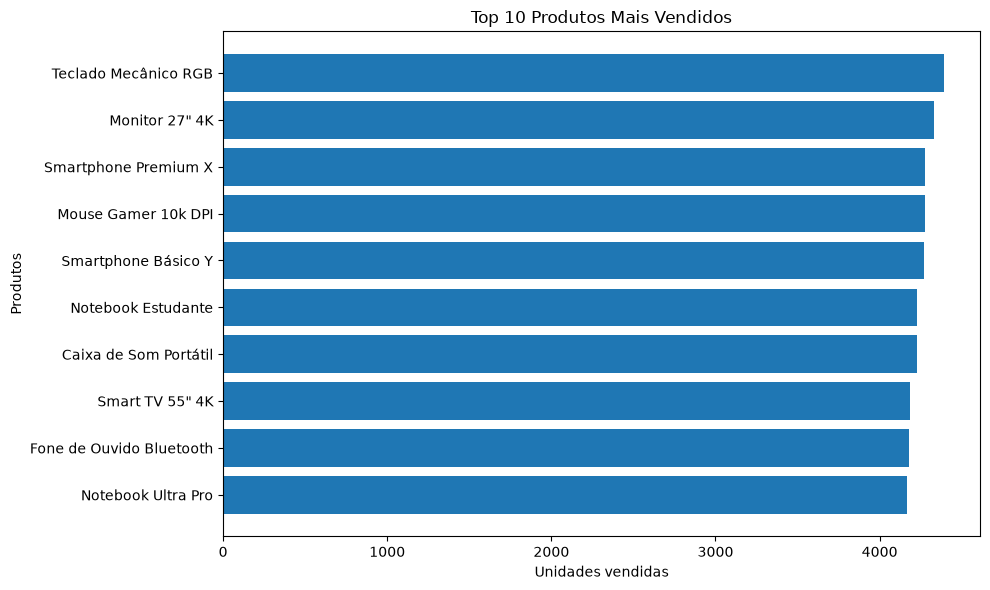

In [29]:
#Selecionando os 10 produtos mais vendidos.
top_10_produtos = vendas_por_produto.head(10).sort_values()

#Criando o gráfico.
plt.figure(figsize=(10, 6))
plt.barh(top_10_produtos.index, top_10_produtos.values)

#Configurando o gráfico.
plt.title('Top 10 Produtos Mais Vendidos')
plt.xlabel('Unidades vendidas')
plt.ylabel('Produtos')

plt.tight_layout()
plt.show()

### Análise dos produtos mais vendidos

O Teclado Mecânico RGB apresentou o maior volume de vendas, com 4.392 unidades comercializadas. Já o Notebook Ultra Pro ocupou a décima posição, com 4.169 unidades.

Os resultados demonstram uma distribuição relativamente equilibrada entre os dez produtos, sem diferenças expressivas no volume de vendas entre as primeiras e últimas posições do ranking.

# 5. Análise do Desempenho por Categoria.

Nesta etapa, será analisado o desempenho financeiro das categorias de produtos, identificando quais apresentam maior participação no faturamento total das vendas concluídas.


In [30]:
#Agrupando as categorias e somando o faturamento líquido.
faturamento_por_categoria = (
    df_vendas_concluidas.groupby('categoria_produto')['valor_total']
    .sum()
    .sort_values(ascending=False)
)

faturamento_por_categoria

categoria_produto
Informática    59441143.88
Eletrônicos    43661789.04
Acessórios      4488259.78
Áudio           2960952.11
Name: valor_total, dtype: float64

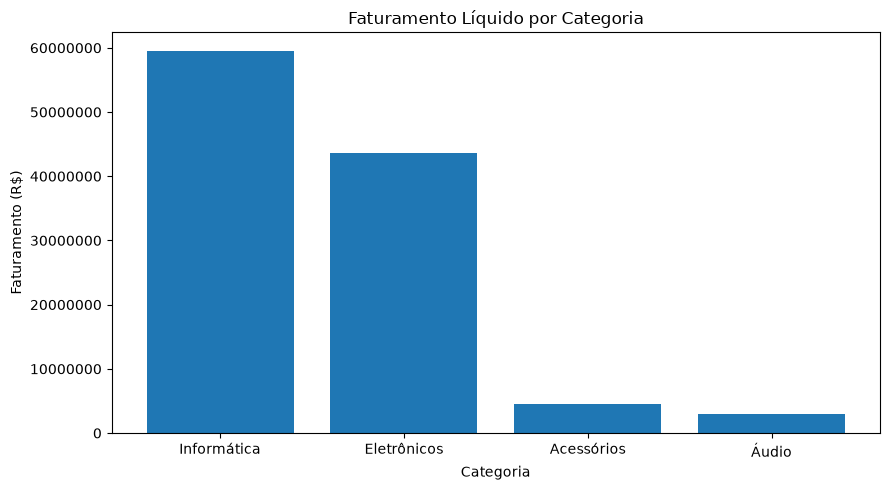

In [31]:
#Criando o gráfico de faturamento por categoria.
plt.figure(figsize=(9, 5))
plt.bar(
    faturamento_por_categoria.index,
    faturamento_por_categoria.values
)

plt.title('Faturamento Líquido por Categoria')
plt.xlabel('Categoria')
plt.ylabel('Faturamento (R$)')

plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

### Análise do faturamento por categoria

A categoria Informática apresentou o maior faturamento líquido, com  59.441.143,88 reais, seguida por Eletrônicos, com 43.661.789,04 reais.

Juntas, essas duas categorias representam aproximadamente 93,3% do faturamento líquido total.

As categorias Acessórios e Áudio apresentaram participações significativamente menores, indicando uma concentração do faturamento nas categorias de Informática e Eletrônicos.

# 6. Análise da Evolução Temporal das Vendas

Nesta etapa, será analisada a evolução do faturamento ao longo dos meses e anos, buscando identificar tendências,

In [32]:
#Removendo registros sem datas válidas para as análises temporais.
df_vendas_temporal =  df_vendas_concluidas.dropna(
    subset=['data_venda']
).copy()

#Conferindo a quantidade de registros após o filtro.
df_vendas_temporal.shape

(42304, 15)

In [33]:
#Agrupando o faturamento líquido por mês.
faturamento_mensal = (
    df_vendas_temporal
    .groupby(df_vendas_temporal['data_venda'].dt.to_period('M'))['valor_total']
    .sum()
)

faturamento_mensal

data_venda
2021-01    3125678.08
2021-02    2356990.88
2021-03    2960942.41
2021-04    2728535.85
2021-05    2957965.94
2021-06    2662660.06
2021-07    3049079.62
2021-08    3081047.38
2021-09    2919834.13
2021-10    3012053.99
2021-11    3780032.03
2021-12    4179355.59
2022-01    3113142.10
2022-02    2632670.84
2022-03    2979571.49
2022-04    2765731.75
2022-05    3042267.46
2022-06    2962035.05
2022-07    2486530.65
2022-08    3088617.02
2022-09    3089908.08
2022-10    2619553.05
2022-11    3709859.29
2022-12    3689253.01
2023-01    3354019.42
2023-02    2975020.40
2023-03    2663093.20
2023-04    3133510.77
2023-05    3236756.58
2023-06    2851496.76
2023-07    3082527.12
2023-08    3425270.36
2023-09    2716135.63
2023-10    3240568.53
2023-11    3234472.33
2023-12    3395337.25
Freq: M, Name: valor_total, dtype: float64

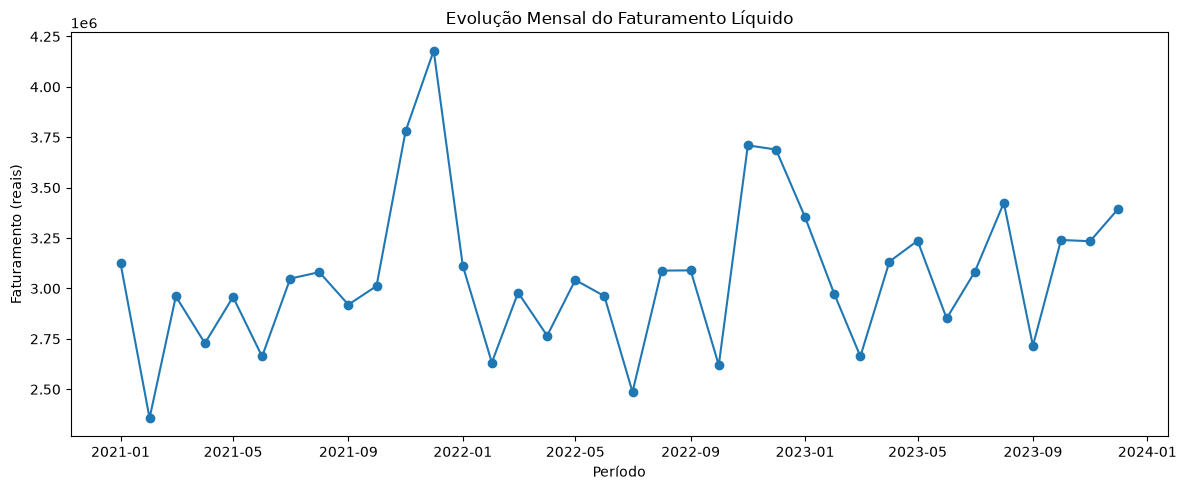

In [34]:
#Criando o gráfico de evolução mensal do faturamento.
plt.figure(figsize=(12, 5))

plt.plot(
    faturamento_mensal.index.to_timestamp(),
    faturamento_mensal.values,
    marker='o'
)

plt.title('Evolução Mensal do Faturamento Líquido')
plt.xlabel('Período')
plt.ylabel('Faturamento (reais)')

plt.tight_layout()
plt.show()


In [35]:
#Agrupando o faturamento líquido por ano.
faturamento_anual = (
    df_vendas_temporal
    .groupby(df_vendas_temporal['data_venda'].dt.year)['valor_total']
    .sum()
)

faturamento_anual

data_venda
2021    36814175.96
2022    36179139.79
2023    37308208.35
Name: valor_total, dtype: float64

In [36]:
#Identificando os meses de maior e menor faturamento.
mes_maior_faturamento =  faturamento_mensal.idxmax()
mes_menor_faturamento = faturamento_mensal.idxmin()

print('Maior faturamento:')
print(mes_maior_faturamento, faturamento_mensal.max())

print('\nMenor faturamento:')
print(mes_menor_faturamento,  faturamento_mensal.min())

Maior faturamento:
2021-12 4179355.59

Menor faturamento:
2021-02 2356990.88


In [37]:
#Calculando a variação percentual do faturamento anual.
variacao_anual = faturamento_anual.pct_change() * 100

variacao_anual

data_venda
2021         NaN
2022   -1.724977
2023    3.120772
Name: valor_total, dtype: float64

### Análise da evolução mensal

O faturamento apresentou oscilações ao longo dos meses analisados. O maior resultado foi registrado em dezembro de 2021, com 4.179.355,59 reais, enquanto fevereiro de 2021 apresentou o menor faturamento, com 2.356.990,88 reais.

### Análise do faturamento anual

Em 2021, o faturamento líquido foi  de 36.814.175,96 reais. Em 2022, houve uma redução de aproximadamente 1,72%, totalizando 36.179.139,79 reais.

Já em 2023, o faturamento alcançou 37.308.208,35 reais, representando um crescimento de aproximadamente 3,12% em relação ao ano anterior.

Os resultados demonstram uma pequena retração em 2022,  seguida de recuperação em 2023, que apresentou o maior faturamento anual do período analisado.

# 7. Análise do Desempenho dos Vendedores

Nesta etapa, será avaliado o desempenho financeiro dos vendedores, identificando os cinco melhores resultados em faturamento líquido e comparando o ticket médio de cada vendedor.

In [38]:
#Agrupando os vendedores  pelo faturamento líquido.
faturamento_por_vendedor = (
    df_vendas_concluidas
    .groupby('nome_vendedor')['valor_total']
    .sum()
    .sort_values(ascending=False)
)

# Selecionando os cinco vendedores com maior faturamento.
top_5_vendedores = faturamento_por_vendedor.head(5)

top_5_vendedores

nome_vendedor
Carlos Eduardo    8092786.32
Fernanda Alves    7873801.31
Otávio Borges     7695066.73
Diana Souza       7539836.11
Julia Martins     7452293.62
Name: valor_total, dtype: float64

In [39]:
#Filtrando os cinco melhores  vendedores.
df_top_5 = df_vendas_concluidas[
    df_vendas_concluidas['nome_vendedor'].isin(top_5_vendedores.index)
]

#Somando o faturamento de cada vendedor.
faturamento = df_top_5.groupby('nome_vendedor')['valor_total'].sum()

#Contando os pedidos únicos de cada vendedor.
pedidos = df_top_5.groupby('nome_vendedor')['id_pedido'].nunique()

#Calculando o ticket médio.
ticket_medio = faturamento / pedidos

#Criando a tabela  de resultados.
desempenho_vendedores = pd.DataFrame({
    'faturamento': faturamento,
    'pedidos': pedidos,
    'ticket_medio': ticket_medio
})

desempenho_vendedores

,faturamento,pedidos,ticket_medio
nome_vendedor,,,
Carlos Eduardo,8092786.32,1681,4814.269078
Diana Souza,7539836.11,1613,4674.417923
Fernanda Alves,7873801.31,1687,4667.339247
Julia Martins,7452293.62,1653,4508.344598
Otávio Borges,7695066.73,1608,4785.489260


### Análise do desempenho dos vendedores

Carlos Eduardo apresentou o maior faturamento, além do maior ticket médio entre os cinco vendedores analisados.

Já Julia Martins apresentou o menor ticket médio do grupo.

Os resultados permitem comparar o desempenho financeiro dos vendedores tanto pelo faturamento total quanto pelo valor médio de seus pedidos.

# 8. Análise das Formas de Pagamento

Nesta etapa,  serão analisadas as formas de pagamento utilizadas nas vendas concluídas, identificando a preferência dos clientes.

In [40]:
#Contabilizando  os pedidos por forma de pagamento.
pedidos_por_pagamento = (
    df_vendas_concluidas
    .groupby('forma_pagamento')['id_pedido']
    .nunique()
    .sort_values(ascending=False)
)

pedidos_por_pagamento

forma_pagamento
Cartão de Crédito    6171
Boleto               6147
PIX                  6132
Cartão de Débito     5900
Name: id_pedido, dtype: int64

In [41]:
#Calculando a participação percentual de cada forma de pagamento.
percentual_pagamento = (
    pedidos_por_pagamento / pedidos_por_pagamento.sum()
) * 100

percentual_pagamento

forma_pagamento
Cartão de Crédito    25.342916
Boleto               25.244353
PIX                  25.182752
Cartão de Débito     24.229979
Name: id_pedido, dtype: float64

### Análise das formas de pagamento

As formas de  pagamento apresentaram participações bastante equilibradas.

O Cartão de Crédito foi o mais utilizado, representando 25,34% dos pedidos, enquanto o Cartão de Débito apresentou a menor participação, com 24,23%.

Os resultados indicam que não  há uma preferência expressiva por uma única modalidade de pagamento.

# 9. Análise Geográfica  das Vendas

Nesta etapa, serão analisados os faturamentos  por estado, identificando quais regiões apresentam os melhores resultados.

In [42]:
#Agrupando o faturamento por estado.
faturamento_por_estado  = (
    df_vendas_concluidas
    .groupby('estado_cliente')['valor_total']
    .sum()
    .sort_values(ascending=False)
)

faturamento_por_estado

estado_cliente
PR    11607314.60
SC    11312569.01
BA    11134190.07
MG    11123202.79
SP    11116714.42
DF    11043685.70
RJ    11029133.37
GO    10958911.70
PE    10948588.97
RS    10277834.18
Name: valor_total, dtype: float64

In [43]:
#Calculando a participação percentual de cada estado.
percentual_por_estado =  (
     faturamento_por_estado / faturamento_por_estado.sum()
) * 100

percentual_por_estado.round(2)

estado_cliente
PR    10.50
SC    10.23
BA    10.07
MG    10.06
SP    10.06
DF     9.99
RJ     9.98
GO     9.91
PE     9.90
RS     9.30
Name: valor_total, dtype: float64

### Análise do faturamento por estado

O Paraná apresentou o maior faturamento, representando 10,50% do total. Já  o Rio Grande do Sul apresentou o menor resultado, com 9,30%.

Os demais estados apresentaram participações próximas, indicando uma distribuição  equilibrada do faturamento entre os  estados analisados.

# 10. Visualização  dos Dados

Nesta etapa, serão apresentados gráficos  para facilitar a interpretação  dos  resultados e destacar os principais indicadores de desempenho das  vendas.

### 10.1  Evolução Mensal  do Faturamento

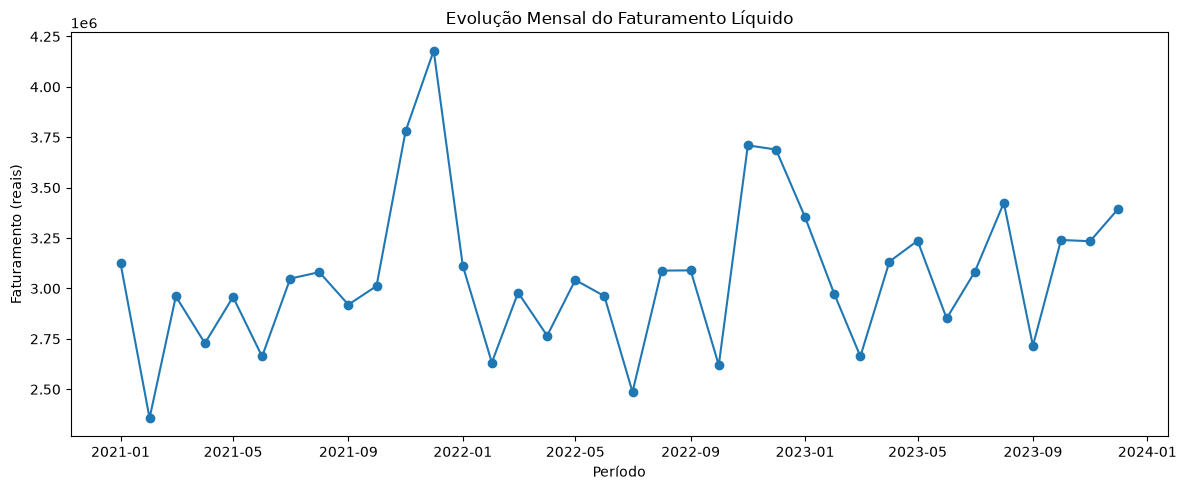

In [61]:
#Criando o gráfico de  evolução mensal do faturamento.
plt.figure(figsize=(12, 5))

plt.plot(
    faturamento_mensal.index.to_timestamp(),
    faturamento_mensal.values,
    marker='o'
)

plt.title('Evolução Mensal do Faturamento Líquido')
plt.xlabel('Período')
plt.ylabel('Faturamento (reais)')

plt.tight_layout()

plt.show()

Esse gráfico  permite observar as oscilações  do faturamento ao longo dos três anos.

###  Faturamento por  Categoria

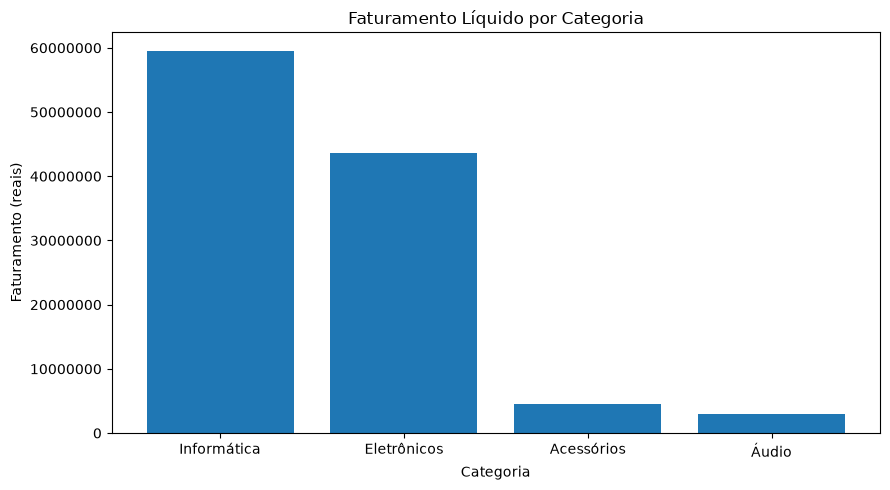

In [45]:
#Criando o gráfico de faturamento por categoria.
plt.figure(figsize=(9, 5))

plt.bar(
    faturamento_por_categoria.index,
    faturamento_por_categoria.values
)

plt.title('Faturamento Líquido por Categoria')
plt.xlabel('Categoria')
plt.ylabel('Faturamento (reais)')

plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

Esse gráfico evidencia a  concentração do faturamento nas categorias de Informática e Eletrônicos.

### Top  10 Produtos  Mais Vendidos

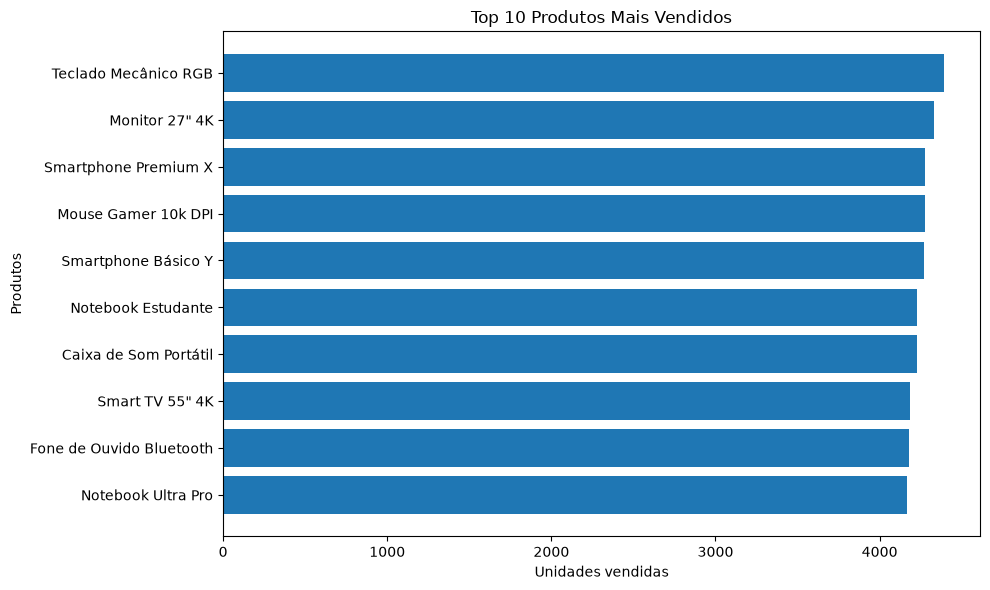

In [46]:
#Selecionando os 10 produtos mais vendidos.
top_10_produtos = vendas_por_produto.head(10).sort_values()

# Criando o gráfico.
plt.figure(figsize=(10, 6))
plt.barh(top_10_produtos.index,  top_10_produtos.values)

plt.title('Top 10 Produtos Mais Vendidos')
plt.xlabel('Unidades vendidas')
plt.ylabel('Produtos')

plt.tight_layout()
plt.show()

Esse gráfico compara  os dez produtos com maior quantidade de unidades vendidas.

### Top 5  Vendedores por Faturamento.


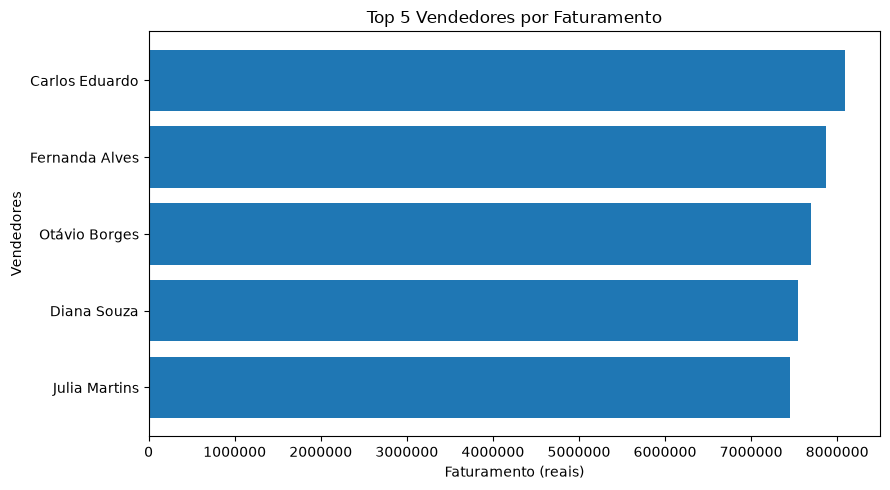

In [47]:
#Ordenando os vendedores pelo  faturamento.
top_5_vendedores_grafico = top_5_vendedores.sort_values()

#Criando o gráfico.
plt.figure(figsize=(9, 5))
plt.barh(
    top_5_vendedores_grafico.index,
    top_5_vendedores_grafico.values
)

plt.title('Top 5 Vendedores por Faturamento')
plt.xlabel('Faturamento (reais)')
plt.ylabel('Vendedores')

plt.ticklabel_format(axis='x',  style='plain')
plt.tight_layout()
plt.show()

O gráfico permite comparar  o faturamento dos cinco vendedores com melhor desempenho.

### Participação das  Formas de Pagamento

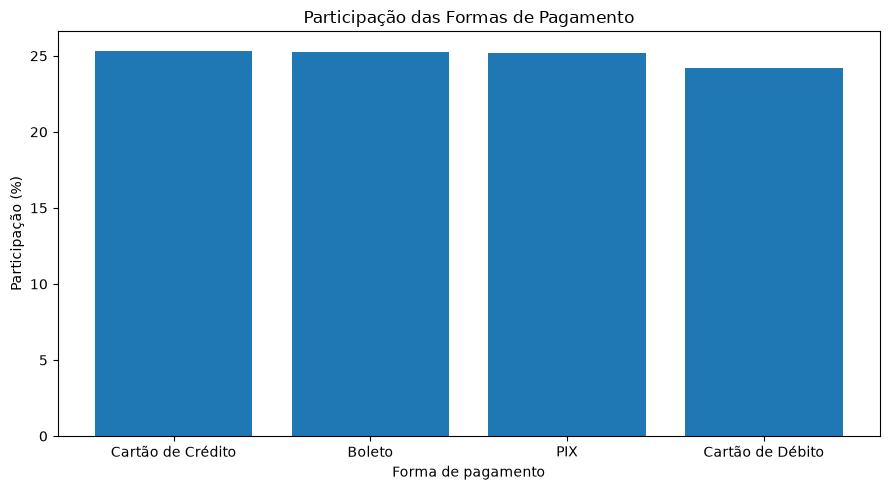

In [48]:
#Criando o gráfico de participação das formas de pagamento.
plt.figure(figsize=(9, 5))

plt.bar(
    percentual_pagamento.index,
    percentual_pagamento.values
)

plt.title('Participação das Formas de Pagamento')
plt.xlabel('Forma de pagamento')
plt.ylabel('Participação (%)')

plt.tight_layout()
plt.show()

Demonstra a distribuição percentual dos pedidos concluídos entre as formas de pagamento.

### Faturamento  por Estado

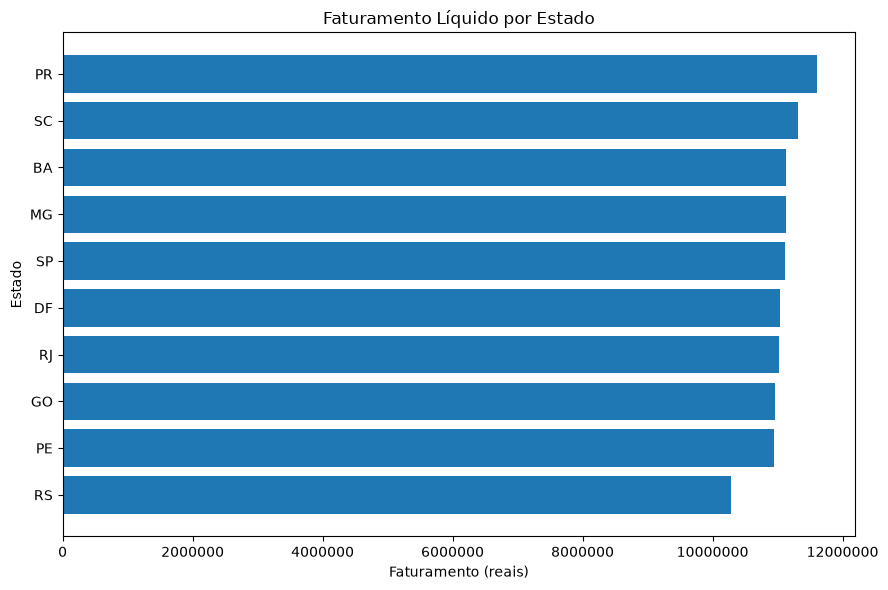

In [49]:
#Ordenando os estados pelo faturamento.
faturamento_estado_grafico  = faturamento_por_estado.sort_values()

# Criando o gráfico.
plt.figure(figsize=(9, 6))
plt.barh(
    faturamento_estado_grafico.index,
    faturamento_estado_grafico.values
)

plt.title('Faturamento Líquido por Estado')
plt.xlabel('Faturamento (reais)')
plt.ylabel('Estado')

plt.ticklabel_format(axis='x', style='plain')
plt.tight_layout()
plt.show()

O gráfico  permite comparar o faturamento líquido entre os dez estados e identificar  os maiores e menores resultados.

### Faturamento  Anual.


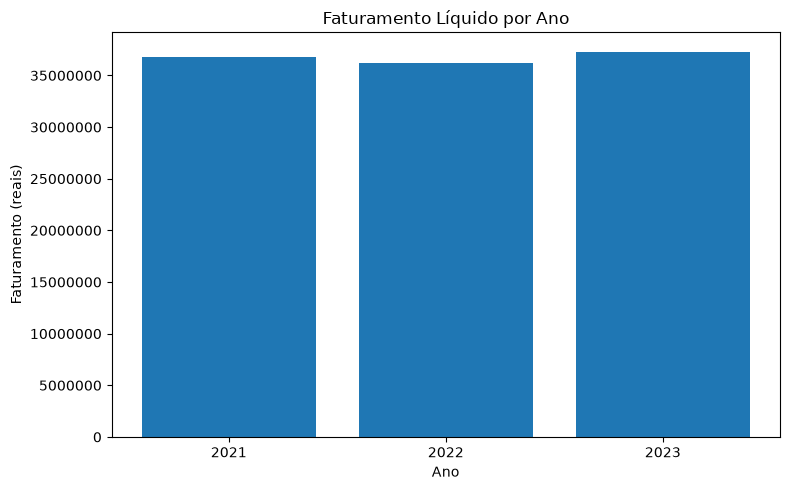

In [50]:
#Criando o gráfico de faturamento anual.
plt.figure(figsize=(8, 5))

plt.bar(
    faturamento_anual.index.astype(str),
    faturamento_anual.values
)

plt.title('Faturamento Líquido por Ano')
plt.xlabel('Ano')
plt.ylabel('Faturamento (reais)')

plt.ticklabel_format(axis='y', style='plain')
plt.tight_layout()
plt.show()

Esse gráfico permite  comparar o faturamento dos três anos e identificar se houve crescimento ou redução no período.

# 11. Estudo Aplicado — Oportunidades Estratégicas de Investimento

### Pergunta de Negócio

Em quais estados e categorias de produtos a empresa deveria concentrar seus investimentos em marketing e força de vendas no próximo trimestre, considerando o faturamento e a evolução do desempenho comercial?

### Metodologia

A investigação será realizada por meio do cruzamento de três dimensões: estado do cliente, categoria do produto e ano da venda.

Serão consideradas apenas as vendas concluídas com datas válidas. O faturamento líquido será agrupado por estado, categoria e ano, permitindo identificar os mercados de maior desempenho e avaliar a evolução dos resultados ao longo do período analisado.

In [51]:
#Criando uma cópia dos dados para o estudo aplicado.
df_estudo = df_vendas_temporal.copy()
#Extraindo o ano da data da venda.
df_estudo['ano'] = df_estudo['data_venda'].dt.year

#Agrupando o faturamento por estado, categoria e ano.
faturamento_estado_categoria = (
    df_estudo
    .groupby(['estado_cliente', 'categoria_produto', 'ano'])['valor_total']
    .sum()
    .sort_values(ascending=False)
)

faturamento_estado_categoria

estado_cliente  categoria_produto  ano 
MG              Informática        2023    2331940.42
SC              Informática        2021    2238557.38
SP              Informática        2021    2228205.20
PR              Informática        2021    2175095.66
SC              Informática        2023    2117107.09
                                              ...    
PE              Áudio              2021      87953.65
RJ              Áudio              2022      87634.57
                                   2023      83100.15
SP              Áudio              2021      81666.04
MG              Áudio              2022      81476.03
Name: valor_total, Length: 120, dtype: float64

Temos 120 combinações, resultado de 10 estados × 4 categorias × 3 anos.

### Faturamento por estado e categoria

In [52]:
#Agrupando o faturamento por estado e categoria.
faturamento_por_estado_categoria = (
    df_estudo
    .groupby(['estado_cliente', 'categoria_produto'])['valor_total']
    .sum()
    .sort_values(ascending=False)
)

faturamento_por_estado_categoria

estado_cliente  categoria_produto
SC              Informática          6408514.70
PR              Informática          6147322.92
MG              Informática          6089966.82
SP              Informática          5997243.94
BA              Informática          5980542.93
DF              Informática          5942325.45
GO              Informática          5897476.20
RJ              Informática          5827519.77
PE              Informática          5597452.39
RS              Informática          5435788.72
PR              Eletrônicos          4649702.12
PE              Eletrônicos          4595502.64
RJ              Eletrônicos          4451040.01
BA              Eletrônicos          4383143.62
DF              Eletrônicos          4358235.50
SP              Eletrônicos          4338474.60
MG              Eletrônicos          4264287.42
GO              Eletrônicos          4257336.27
SC              Eletrônicos          4154244.74
RS              Eletrônicos          4097130.07
GO    

A categoria Informática lidera o faturamento em todos os dez estados.

Isso sugere uma oportunidade de investimento na categoria Informática, especialmente em Santa Catarina.



 ### Evolução das cinco principais combinações

In [54]:
#Organizando o faturamento por ano em colunas.
faturamento_anual_estado_categoria = (
    faturamento_estado_categoria.unstack('ano')
)

#Selecionando as cinco combinações com maior faturamento acumulado.
top_5_combinacoes = faturamento_por_estado_categoria.head(5).index

#Consultando a evolução anual dessas combinações.
faturamento_top_5 = faturamento_anual_estado_categoria.loc[
    top_5_combinacoes
]

faturamento_top_5

,ano,2021,2022,2023
estado_cliente,categoria_produto,,,
SC,Informática,2238557.38,2052850.23,2117107.09
PR,Informática,2175095.66,2026796.54,1945430.72
MG,Informática,1768150.63,1989875.77,2331940.42
SP,Informática,2228205.20,1870785.44,1898253.30
BA,Informática,1855640.60,2046677.38,2078224.95


O que chama atenção:

    Minas Gerais: crescimento consistente, com aproximadamente 32% de aumento entre 2021 e 2023.
    Bahia: também apresenta crescimento nos três anos.
    Santa Catarina: continua liderando no acumulado, mas perdeu força em relação a 2021.
    Paraná: apresenta queda nos três anos.

Isso sugere que Minas Gerais e Bahia podem representar oportunidades interessantes de investimento, especialmente para a categoria Informática.

### Evolução do Faturamento nas Cinco Principais Combinações

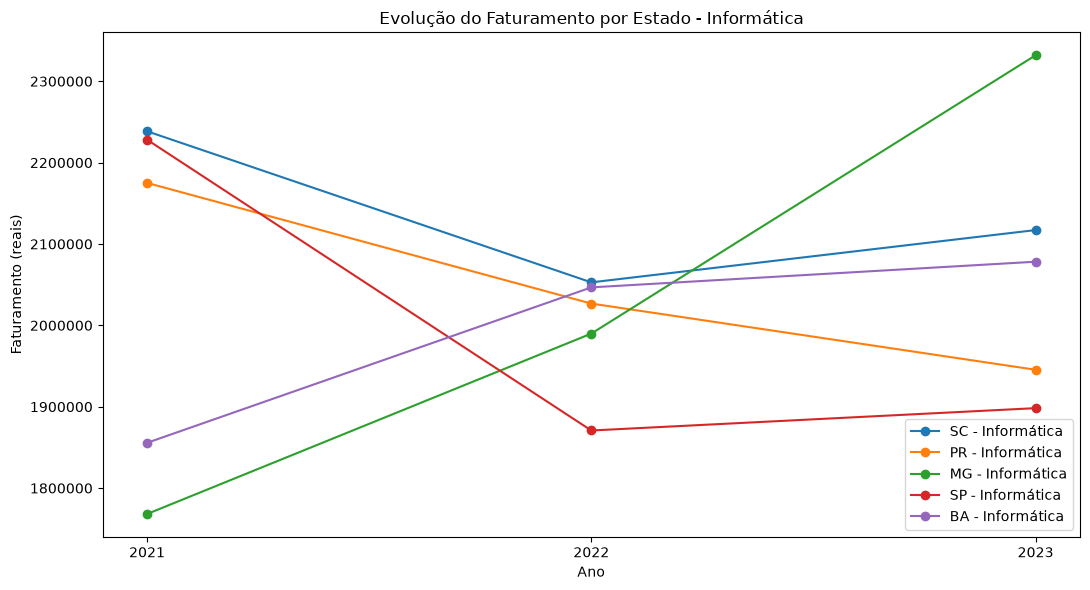

In [58]:
#Criando o gráfico de evolução anual.
plt.figure(figsize=(11, 6))

plt.plot(faturamento_top_5.columns, faturamento_top_5.iloc[0], marker='o', label='SC - Informática')
plt.plot(faturamento_top_5.columns, faturamento_top_5.iloc[1], marker='o', label='PR - Informática')
plt.plot(faturamento_top_5.columns, faturamento_top_5.iloc[2], marker='o', label='MG - Informática')
plt.plot(faturamento_top_5.columns, faturamento_top_5.iloc[3], marker='o', label='SP - Informática')
plt.plot(faturamento_top_5.columns, faturamento_top_5.iloc[4], marker='o', label='BA - Informática')

plt.title('Evolução do Faturamento por Estado - Informática')
plt.xlabel('Ano')
plt.ylabel('Faturamento (reais)')

plt.ticklabel_format(axis='y', style='plain')
plt.legend()
plt.tight_layout()
plt.xticks([2021, 2022, 2023])
plt.show()

### Interpretação dos Resultados

A análise demonstrou que Minas Gerais apresentou o crescimento mais expressivo entre as cinco combinações avaliadas, passando de aproximadamente 1,77 milhão de reais em 2021 para 2,33 milhões em 2023.

A Bahia também apresentou crescimento contínuo durante o período, enquanto Santa Catarina registrou recuperação parcial após a queda de 2022.

Por outro lado, Paraná apresentou redução contínua no faturamento, e São Paulo demonstrou uma recuperação pouco expressiva em 2023.

Esses resultados indicam que Minas Gerais e Bahia merecem atenção especial na definição das estratégias comerciais, especialmente na categoria Informática.

 # Conclusão Executiva

Com base nos resultados, recomenda-se concentrar a maior parte dos investimentos adicionais de marketing e força de vendas na categoria Informática, priorizando os estados de Minas Gerais e Bahia. Minas Gerais apresentou o crescimento mais expressivo, passando de 1.768.150,63 reais em 2021 para 2.331.940,42 reais em 2023, enquanto a Bahia apresentou crescimento contínuo, alcançando 2.078.224,95 reais em 2023. Santa Catarina, apesar de apresentar o maior faturamento acumulado entre as combinações analisadas, merece ações de manutenção e fortalecimento, considerando a redução em relação a 2021. Já Paraná e São Paulo exigem uma avaliação mais criteriosa antes de receber novos investimentos, devido à queda observada no período. Dessa forma, a estratégia recomendada é priorizar mercados com crescimento consistente, preservar os mercados de maior faturamento e reavaliar aqueles que apresentam retração. Essa recomendação considera o faturamento como indicador de desempenho, uma vez que a base não contém informações sobre custos, margens de lucro ou retorno direto das campanhas de marketing.